# 07 · Monitoring and Anomaly Detection

**Goal:** catch unusual weeks automatically, then explain **why** the number moved before anyone asks.

Approach:

1. **Flag** a week when a metric is unusually far from normal: more than 3 standard deviations away from the average of the previous 8 weeks. In plain terms, a move that size would happen by chance well under 1% of the time.
2. **Explain** each flag: was it caused by one player, or by many players at once?
3. **Investigate** the most interesting cases.

The window starts in January 2016, after the cohort's onboarding period, when week-to-week movement reflects normal business rather than the launch curve.

Reads `agg_weekly_kpis`, `fct_player_week`, `dim_player`, `stg_deposits`. Exports `outputs/alerts.csv`.

In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
con = sqlite3.connect(ROOT / "data" / "poker.db")
NAVY, GREY, RED = "#1f4e79", "#8c8c8c", "#b22222"
START, WINDOW, THRESHOLD = "2016-01-04", 8, 3.0

def q(sql):
    return pd.read_sql_query(sql, con)

kpis = q("select * from agg_weekly_kpis")
kpis["week_start"] = pd.to_datetime(kpis.week_start)
pw = q("select f.*, d.market from fct_player_week f join dim_player d on d.player_id = f.player_id")
pw["week_start"] = pd.to_datetime(pw.week_start)
pw["deposits"] = pw.deposit_amount
pw["stakes"] = pw.total_stakes

## 1. Flag unusual weeks

In [2]:
METRICS = {
    "weekly_active": "Weekly active players",
    "deposits": "Deposits (EUR)",
    "net_deposits": "Net deposits (EUR)",
    "stakes": "Stakes (EUR)",
    "deposit_failure_rate": "Deposit failure rate",
}
rows = []
for m in METRICS:
    base = kpis[m].shift(1).rolling(WINDOW).mean()
    sd = kpis[m].shift(1).rolling(WINDOW).std()
    z = (kpis[m] - base) / sd
    flagged = kpis[(z.abs() >= THRESHOLD) & (kpis.week_start >= START)]
    for i in flagged.index:
        rows.append({"week_start": kpis.week_start[i], "metric": m, "value": kpis[m][i],
                     "baseline": base[i], "change_vs_baseline": (kpis[m][i] - base[i]) / base[i], "z_score": z[i]})
alerts = pd.DataFrame(rows).sort_values("week_start").reset_index(drop=True)
print(f"{len(alerts)} alerts across {kpis[kpis.week_start >= START].shape[0]} weeks")
alerts.groupby("metric").size().rename("alerts").to_frame()

62 alerts across 234 weeks


,alerts
metric,
deposit_failure_rate,11
deposits,12
net_deposits,10
stakes,15
weekly_active,14


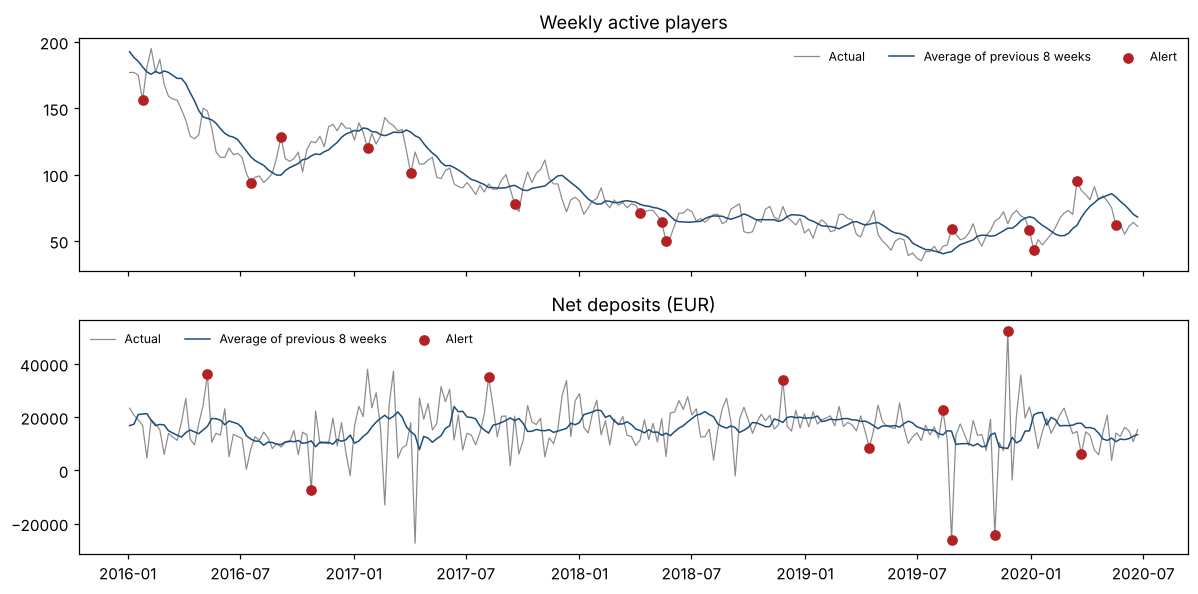

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, m in zip(axes, ["weekly_active", "net_deposits"]):
    k = kpis[kpis.week_start >= START]
    base = kpis[m].shift(1).rolling(WINDOW).mean()[k.index]
    ax.plot(k.week_start, k[m], color=GREY, linewidth=0.8, label="Actual")
    ax.plot(k.week_start, base, color=NAVY, linewidth=1, label="Average of previous 8 weeks")
    a = alerts[alerts.metric == m]
    ax.scatter(a.week_start, a.value, color=RED, zorder=3, label="Alert")
    ax.set_title(METRICS[m]); ax.legend(frameon=False, ncol=3, fontsize=8)
plt.tight_layout()

## 2. Explain each alert automatically

In a business with a few thousand players, one large player can move a weekly total on their own. Before escalating an alert, the first question is: **one player, or everyone?**

- For money metrics, compare each player's value this week with their own average over the previous 8 weeks, and measure how much of the total change the biggest mover explains.
- For the deposit failure rate, recalculate the rate without the player with the most failed attempts.
- For weekly active players, check how many markets moved in the same direction.

In [4]:
def explain(week, metric):
    week = pd.Timestamp(week)
    prior = pw[(pw.week_start < week) & (pw.week_start >= week - pd.Timedelta(weeks=WINDOW))]
    this = pw[pw.week_start == week]

    if metric in ("deposits", "net_deposits", "stakes"):
        now = this.groupby("player_id")[metric].sum()
        before = prior.groupby("player_id")[metric].sum() / WINDOW
        delta = now.reindex(now.index.union(before.index), fill_value=0) - before.reindex(now.index.union(before.index), fill_value=0)
        total = delta.sum()
        top = delta.abs().idxmax()
        share = delta[top] / total if total else np.nan
        driver = "one player" if share >= 0.5 else "many players"
        return driver, f"Top player explains {share:.0%} of the change (EUR {delta[top]:,.0f} of EUR {total:,.0f})"

    if metric == "deposit_failure_rate":
        d = q(f"""select player_id, is_completed from stg_deposits
                 where request_date between '{week:%Y-%m-%d}' and '{week + pd.Timedelta(days=6):%Y-%m-%d}'""")
        fails = (1 - d.is_completed).groupby(d.player_id).sum()
        top = fails.idxmax()
        rest = d[d.player_id != top]
        rate_all, rate_rest = 1 - d.is_completed.mean(), 1 - rest.is_completed.mean()
        base = kpis.set_index("week_start").deposit_failure_rate.shift(1).rolling(WINDOW).mean()[week]
        driver = "one player" if abs(rate_rest - base) < abs(rate_all - base) / 2 else "many players"
        return driver, (f"Failure rate {rate_all:.0%} with all players, {rate_rest:.0%} without the top player "
                        f"({int(fails[top])} failed attempts); baseline {base:.0%}")

    if metric == "weekly_active":
        now = this[this.poker_active == 1].groupby("market").size()
        before = prior[prior.poker_active == 1].groupby("market").size() / WINDOW
        mk = pd.concat([now, before], axis=1, keys=["now", "before"]).fillna(0)
        mk = mk[mk.before >= 2]
        direction = np.sign((now.sum() - before.sum()))
        same = (np.sign(mk.now - mk.before) == direction).mean()
        driver = "many players" if same >= 0.6 else "some markets"
        return driver, f"{same:.0%} of markets moved in the same direction"

alerts[["driver", "explanation"]] = alerts.apply(lambda r: pd.Series(explain(r.week_start, r.metric)), axis=1)
alerts.to_csv(ROOT / "outputs" / "alerts.csv", index=False)
alerts.groupby(["metric", "driver"]).size().unstack(fill_value=0)

driver,many players,one player,some markets
metric,,,
deposit_failure_rate,10,1,0
deposits,5,7,0
net_deposits,3,7,0
stakes,3,12,0
weekly_active,13,0,1


In [5]:
show = alerts.copy()
show["week_start"] = show.week_start.dt.strftime("%Y-%m-%d")
show["change_vs_baseline"] = show.change_vs_baseline.map("{:+.0%}".format)
show["value"] = [f"{v:.1%}" if m == "deposit_failure_rate" else f"{v:,.0f}" for m, v in zip(show.metric, show.value)]
pd.set_option("display.max_colwidth", 110)
show[["week_start", "metric", "value", "change_vs_baseline", "driver", "explanation"]]

,week_start,metric,value,change_vs_baseline,driver,explanation
0,2016-01-25,weekly_active,156,-14%,many players,75% of markets moved in the same direction
1,2016-01-25,stakes,"549,398",+342%,one player,"Top player explains 117% of the change (EUR 497,356 of EUR 425,225)"
2,2016-05-02,deposits,"46,840",+62%,one player,"Top player explains 76% of the change (EUR 13,646 of EUR 17,899)"
3,2016-05-09,net_deposits,"36,088",+118%,one player,"Top player explains 97% of the change (EUR 18,959 of EUR 19,538)"
4,2016-07-18,weekly_active,94,-17%,many players,75% of markets moved in the same direction
...,...,...,...,...,...,...
57,2020-03-16,weekly_active,95,+54%,many players,100% of markets moved in the same direction
58,2020-03-23,net_deposits,"6,146",-65%,one player,"Top player explains 59% of the change (EUR -6,798 of EUR -11,558)"
59,2020-03-30,stakes,"53,473",+184%,one player,"Top player explains 70% of the change (EUR 24,324 of EUR 34,657)"
60,2020-04-27,deposit_failure_rate,26.3%,+58%,many players,"Failure rate 26% with all players, 24% without the top player (17 failed attempts); baseline 17%"


**Most money alerts are caused by one player:** 26 of the 37 alerts on deposits, net deposits and stakes. In a small player base, a single large deposit or cash-out moves the weekly total more than any real trend. A monitoring report that only shows totals would send leadership chasing noise; showing the driver next to every alert prevents that. (A share above 100% means other players moved the opposite way, so the top player more than explains the change.)

**Activity and failure-rate alerts are the opposite:** almost all are caused by many players at once. When the failure rate moves, it usually moves for everyone, which points to a payment provider or bank-side change and belongs with the payments team.

## 3. Case studies

### Case 1: a whole week of negative net deposits from one cash-out

In [6]:
w = pd.Timestamp("2019-08-26")
top = pw[pw.week_start == w].nsmallest(3, "net_deposits")[["market", "deposits", "withdrawal_amount", "net_deposits"]]
print(alerts[(alerts.week_start == w) & (alerts.metric == "net_deposits")].explanation.iloc[0])
top

Top player explains 108% of the change (EUR -44,156 of EUR -40,771)


,market,deposits,withdrawal_amount,net_deposits
0,Netherlands,0.0000,44231.0300,-44231.0300
1,Rest of World,81.2926,718.2431,-636.9505
2,Germany,0.0000,390.0000,-390.0000


Net deposits for the whole cohort turned negative because one player withdrew about EUR 44,000. Nothing is wrong with the business that week. The right action is to confirm the withdrawal was a normal win, note it in the weekly summary, and let the VIP team check in with the player.

### Case 2: a deposit failure spike that was not a payment outage

In [7]:
w = "2018-07-16"
print(alerts[(alerts.week_start == pd.Timestamp(w)) & (alerts.metric == "deposit_failure_rate")].explanation.iloc[0])
q(f"""
select row_number() over (order by count(*) desc) as player_rank, pay_method, count(*) as attempts, sum(is_completed) as completed
from stg_deposits
where request_date between '{w}' and date('{w}', '+6 days')
group by player_id, pay_method order by attempts desc limit 5
""")

Failure rate 35% with all players, 23% without the top player (115 failed attempts); baseline 21%


,player_rank,pay_method,attempts,completed
0,1,PayPal,106,3
1,2,VISA,32,14
2,3,DirectPay24,24,15
3,4,PayPal,22,4
4,5,VISA,20,20


The failure rate jumped to 35%, and PayPal looked broken. In fact one player made over 100 PayPal attempts in a week and only 3 went through; without that player the rate is in its normal range.

That changes who should act. It is **not** a ticket for the payments provider. Repeated declined deposits are a known risk signal, both for fraud and for problem gambling, so this player should be routed to the risk and safer-gambling teams.

### Case 3: the first COVID-19 lockdown, a real change across many players

In [8]:
w = pd.Timestamp("2020-03-16")
prior = pw[(pw.week_start < w) & (pw.week_start >= w - pd.Timedelta(weeks=WINDOW))]
now = pw[(pw.week_start == w) & (pw.poker_active == 1)].groupby("market").size()
before = prior[prior.poker_active == 1].groupby("market").size() / WINDOW
covid = pd.concat([now, before.round(1)], axis=1, keys=["active_this_week", "avg_previous_8_weeks"]).fillna(0)
covid["change"] = (covid.active_this_week / covid.avg_previous_8_weeks - 1).map("{:+.0%}".format)
covid.sort_values("active_this_week", ascending=False).head(6)

,active_this_week,avg_previous_8_weeks,change
market,,,
Germany,27.0,16.5,+64%
France,25.0,13.8,+81%
Belgium,16.0,13.2,+21%
Rest of World,10.0,6.6,+52%
Spain,8.0,6.0,+33%
Austria,3.0,2.5,+20%


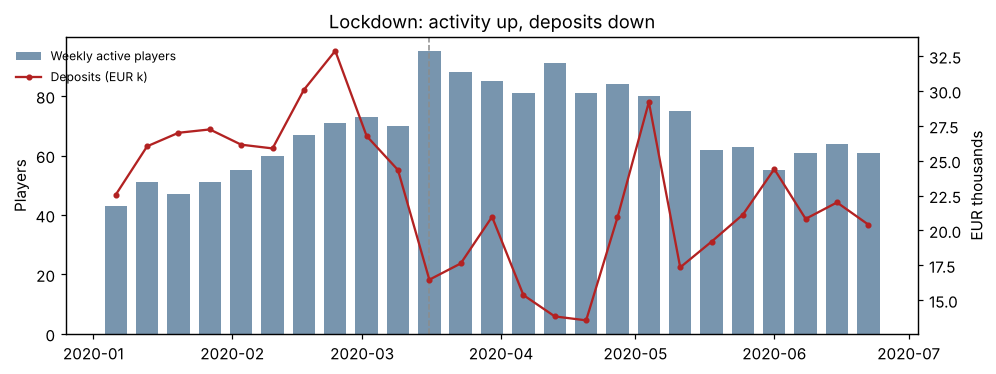

In [9]:
k = kpis[(kpis.week_start >= "2020-01-06") & (kpis.week_start <= "2020-06-22")]
fig, ax1 = plt.subplots(figsize=(10, 3.5))
ax1.bar(k.week_start, k.weekly_active, width=5, color=NAVY, alpha=0.6, label="Weekly active players")
ax2 = ax1.twinx()
ax2.plot(k.week_start, k.deposits / 1000, color=RED, marker="o", markersize=3, label="Deposits (EUR k)")
ax1.axvline(pd.Timestamp("2020-03-16"), color=GREY, linestyle="--", linewidth=1)
ax1.set_title("Lockdown: activity up, deposits down"); ax1.set_ylabel("Players"); ax2.set_ylabel("EUR thousands")
fig.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.07, 0.88), fontsize=8)

Activity had been rising gradually since early February, from about 45 weekly players in January to about 70 by early March, and then jumped in the lockdown week. The jump shows up in every major market at once, so it is a real change in behaviour, not one player. Lapsed players came back (reactivations more than doubled that week, notebook 04), but deposits fell.

Why deposits fell is not something this data can answer. One possible explanation is that returning players used balances already in their accounts, but there is no balance field to confirm it.

For leadership the message is: **engagement is up, revenue is not yet**. Watch whether deposits catch up over the next weeks before planning around the higher activity, and consider targeted offers to the reactivated players while they are engaged.

## 4. How this would run in production

| Step | What it does |
|---|---|
| Weekly job | Recalculate the KPIs and the average of the previous 8 weeks |
| Alert rule | Flag metrics more than 3 standard deviations from the baseline |
| Driver check | Attach "one player" or "many players" with the top contributor |
| Routing | Many-player alerts go to leadership in the weekly summary; one-player alerts go to VIP, risk, or safer-gambling teams |

## Takeaways

1. **Explain before escalating.** Most money alerts were driven by one player, while activity and failure-rate alerts were caused by many players at once. Adding the driver to every alert avoids false alarms and sends each alert to the right team.
2. **The same spike can belong to different teams.** A failure-rate spike looked like a payment outage but was a single player's repeated declines, a risk signal rather than a provider issue.
3. **Shifts across many players deserve a leadership note.** The lockdown lifted activity everywhere while deposits fell, an early warning that engagement and revenue had separated.

In [10]:
con.close()